<a href="https://colab.research.google.com/github/carollinemelloo/ProcessamentoDeImagens/blob/main/Portfolio01bi2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from skimage import data

In [8]:
def convolucao(imagem, tamanho_kernel, funcao_operacao):
    altura, largura = imagem.shape
    pad = tamanho_kernel // 2

    img_padded = np.pad(imagem, pad, mode='edge')
    img_filtrada = np.zeros_like(imagem, dtype=np.float32)

    for i in range(altura):
        for j in range(largura):
            vizinhanca = img_padded[i:i + tamanho_kernel, j:j + tamanho_kernel]
            img_filtrada[i, j] = funcao_operacao(vizinhanca)

    return np.clip(img_filtrada, 0, 255).astype(np.uint8)

In [9]:
def filtro_media(imagem, tamanho_kernel=3):
    return convolucao(imagem, tamanho_kernel, lambda v: np.mean(v))

def filtro_mediana(imagem, tamanho_kernel=3):
    return convolucao(imagem, tamanho_kernel, lambda v: np.median(v))

def filtro_moda(imagem, tamanho_kernel=3):
    return convolucao(imagem, tamanho_kernel, lambda v: stats.mode(v.ravel(), keepdims=False)[0])

def filtro_maxima(imagem, tamanho_kernel=3):
    return convolucao(imagem, tamanho_kernel, lambda v: np.max(v))

array([[200, 200, 200, ..., 189, 190, 190],
       [200, 199, 199, ..., 190, 190, 190],
       [199, 199, 199, ..., 190, 190, 190],
       ...,
       [ 25,  25,  27, ..., 139, 122, 147],
       [ 25,  25,  26, ..., 158, 141, 168],
       [ 25,  25,  27, ..., 151, 152, 149]], shape=(512, 512), dtype=uint8)
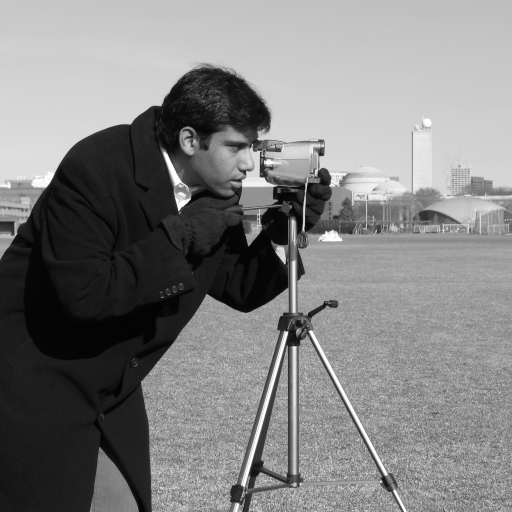

In [13]:
imagem_gray = data.camera()

img_ruido = imagem_gray.copy()
prob = 0.05
rnd = np.random.rand(*img_ruido.shape)
img_ruido[rnd < prob / 2] = 0
img_ruido[rnd > 1 - prob / 2] = 255

imagem_gray

In [11]:
tamanho_k = 3

img_media = filtro_media(img_ruido, tamanho_k)
img_mediana = filtro_mediana(img_ruido, tamanho_k)
img_moda = filtro_moda(img_ruido, tamanho_k)
img_maxima = filtro_maxima(img_ruido, tamanho_k)

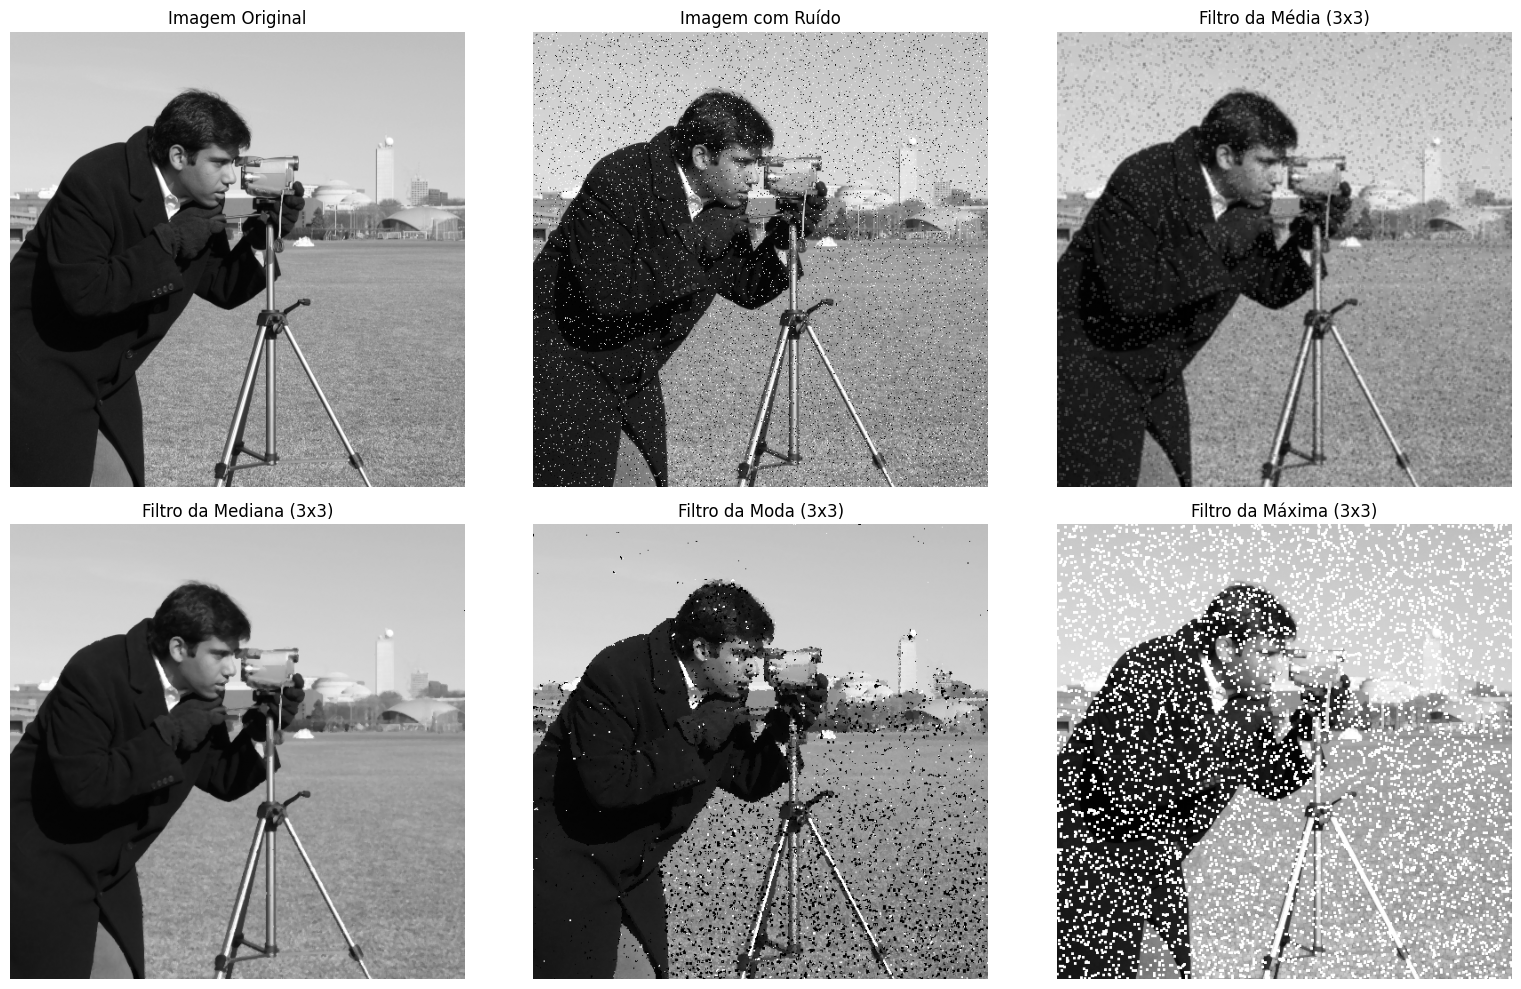

In [12]:
plt.figure(figsize=(16, 10))

plt.subplot(2, 3, 1)
plt.imshow(imagem_gray, cmap='gray')
plt.title('Imagem Original')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(img_ruido, cmap='gray')
plt.title('Imagem com Ruído')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(img_media, cmap='gray')
plt.title(f'Filtro da Média ({tamanho_k}x{tamanho_k})')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(img_mediana, cmap='gray')
plt.title(f'Filtro da Mediana ({tamanho_k}x{tamanho_k})')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(img_moda, cmap='gray')
plt.title(f'Filtro da Moda ({tamanho_k}x{tamanho_k})')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(img_maxima, cmap='gray')
plt.title(f'Filtro da Máxima ({tamanho_k}x{tamanho_k})')
plt.axis('off')

plt.tight_layout()
plt.show()

## Conclusão

**Mediana:** Apresentou o melhor resultado, removendo o ruído e mantendo a definição dos detalhes da imagem.

**Média:** Suavizou a intensidade do ruído, mas causou um desfoque (borrão) visível em toda a imagem.

**Moda:** Ineficaz na remoção dos pontos escuros, mantendo grande parte do ruído visível.

**Máxima:** Eliminou os pontos pretos, mas ampliou e espalhou os pontos brancos por toda a imagem.

O filtro da **Mediana** é o mais adequado para tratar este tipo de ruído impulsivo.